# SETSUNA demo

SETSUNA infers spikes from calcium imaging on a time grid finer than the imaging frame. This notebook runs it on one
jGCaMP8s neuron whose spikes were recorded electrically at the same time, and compares the inferred spikes with the
recorded ones.

**Data.** `jGCaMP8s_ANM479572_cell08.npz` (0.2 MB, in this folder): raw and neuropil fluorescence, frame times and
loose-seal spike times of one neuron from DANDI:000168 (Zhang, Rózsa et al., *Nature* 2023), CC BY 4.0; see
`DATA_LICENSE.md`. The neuron is part of the public ground truth SETSUNA was trained on, so this notebook shows how to
run the software and what it returns, not held-out accuracy.

**Requirements.** `pip install setsuna matplotlib` (see the user guide for PyTorch with CUDA). The trained models
(about 64 MB) are downloaded the first time SETSUNA runs. The whole notebook runs in well under a minute.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import setsuna

print("setsuna", setsuna.__version__)

setsuna 0.9.0


## 1. Load the recording

The neuron was imaged at 122 Hz. To mimic a typical experiment, keep every fourth frame (30.5 Hz).

In [2]:
d = np.load("jGCaMP8s_ANM479572_cell08.npz")
step = 4
F, Fneu, t = d["F"][::step], d["Fneu"][::step], d["frame_times"][::step]
fps = float(d["fps"]) / step
t = t - t[0]
spikes = d["spike_times"] - d["frame_times"][0]
spikes = spikes[(spikes >= 0) & (spikes < t[-1] + 1 / fps)]
print(f"{len(t)} frames, {len(t) / fps:.0f} s at {fps:.1f} Hz, {len(spikes)} recorded spikes")

5185 frames, 170 s at 30.5 Hz, 127 recorded spikes


## 2. dF/F

SETSUNA reads fractional dF/F (0.5 = a 50% increase). From raw and neuropil fluorescence, use its own function
(neuropil coefficient 0.7, a 60-s maximin baseline).

In [3]:
dff = setsuna.dff_from_fluorescence(F[None], Fneu[None], fps=fps)
print(dff.shape)

(1, 5185)


## 3. Infer spikes

`tolerance_ms` is the spike-timing precision the analysis needs (here 25 ms). `bins_per_frame=16` also returns the
sub-frame streams pooled to 16 bins per frame. This demo runs on the CPU; use `device="auto"` to run on a GPU.

In [4]:
t0 = time.time()
out = setsuna.infer(dff, fps=fps, indicator="jGCaMP8s", cell_type="pyramidal",
                    tolerance_ms=25, bins_per_frame=16, device="cpu")
print(f"run time {time.time() - t0:.1f} s (including loading the models)")
print("outputs:", {k: (v.shape if hasattr(v, "shape") else type(v).__name__) for k, v in out.items()})

run time 2.5 s (including loading the models)
outputs: {'rate': (1, 5185), 'nu': (1,), 'fps': 'float', 'indicator': 'str', 'cell_type': 'str', 'band': 'str', 'tolerance_ms': 'int', 'spike_times': 'list', 'count': (1, 82960), 'prob': (1, 82960), 'bins_per_frame': 'int', 'spike_counts': (1, 82960)}


`rate` is the expected number of spikes in each frame, `spike_times` the decoded spike times (s), `nu` the noise
level, and `count`, `prob` and `spike_counts` the sub-frame streams (16 bins per frame here).

## 4. Compare with the recorded spikes

In [5]:
rate, inferred = out["rate"][0], out["spike_times"][0]

def matched(true_t, inferred_t, tol_s):
    """Recorded spikes with an inferred spike within +-tol_s, one-to-one, in time order."""
    used = np.zeros(len(inferred_t), bool)
    n = 0
    for s in true_t:
        j = np.flatnonzero(~used & (np.abs(inferred_t - s) <= tol_s))
        if j.size:
            used[j[np.argmin(np.abs(inferred_t[j] - s))]] = True
            n += 1
    return n

print(f"recorded spikes : {len(spikes)}")
print(f"expected spikes : {rate.sum():.1f} (sum of the rate)")
print(f"inferred spikes : {len(inferred)}")
for tol in (0.025, 0.1):
    m = matched(spikes, inferred, tol)
    print(f"within +-{tol * 1000:.0f} ms : {m} of {len(spikes)} recorded spikes ({100 * m / len(spikes):.0f}%)")

recorded spikes : 127
expected spikes : 121.4 (sum of the rate)
inferred spikes : 121
within +-25 ms : 95 of 127 recorded spikes (75%)
within +-100 ms : 105 of 127 recorded spikes (83%)


## 5. Plot

Top, 30 s of dF/F with the recorded (black) and inferred (blue) spikes; middle, the rate per frame; bottom, a 2-s zoom with
the sub-frame count stream (16 bins per frame) and the frame boundaries.

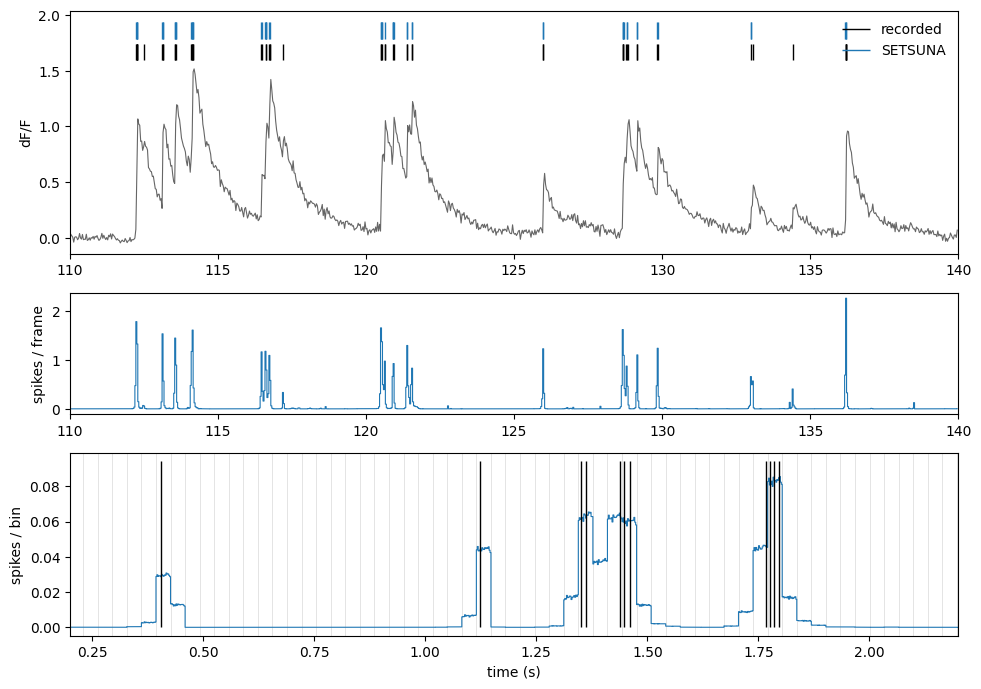

In [6]:
win = (110, 140)          # 30 s with many spikes
k = out["bins_per_frame"]
tf = np.arange(rate.size * k) / (fps * k)
sel = (t >= win[0]) & (t < win[1])
fig, ax = plt.subplots(3, 1, figsize=(10, 7), gridspec_kw={"height_ratios": [2, 1, 1.5]})
ax[0].plot(t[sel], dff[0, sel], color="0.4", lw=0.8)
ymax = dff[0, sel].max()
rs = spikes[(spikes >= win[0]) & (spikes < win[1])]
ins = inferred[(inferred >= win[0]) & (inferred < win[1])]
ax[0].vlines(rs, ymax * 1.05, ymax * 1.15, color="k", lw=1, label="recorded")
ax[0].vlines(ins, ymax * 1.18, ymax * 1.28, color="tab:blue", lw=1, label="SETSUNA")
ax[0].set_ylabel("dF/F"); ax[0].legend(loc="upper right", frameon=False); ax[0].set_xlim(win)
ax[1].step(t[sel], rate[sel], where="post", color="tab:blue", lw=0.8)
ax[1].set_ylabel("spikes / frame"); ax[1].set_xlim(win)
z = (0.2, 2.2)            # a single spike and two bursts
sz = (tf >= z[0]) & (tf < z[1])
ax[2].step(tf[sz], out["count"][0, sz], where="post", color="tab:blue", lw=0.8)
for fb in t[(t >= z[0]) & (t < z[1])]:
    ax[2].axvline(fb, color="0.85", lw=0.5, zorder=0)
zr = spikes[(spikes >= z[0]) & (spikes < z[1])]
ax[2].vlines(zr, 0, out["count"][0, sz].max() * 1.1 if sz.any() else 1, color="k", lw=1)
ax[2].set_xlim(z); ax[2].set_ylabel("spikes / bin"); ax[2].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## 6. Rates only

Without spike times (`tolerance_ms=None`), SETSUNA returns only `rate` and `nu`, which is faster for large
recordings.

In [7]:
r = setsuna.infer(dff, fps=fps, indicator="jGCaMP8s", tolerance_ms=None, device="cpu")
print(sorted(r.keys()))

['band', 'cell_type', 'fps', 'indicator', 'nu', 'rate', 'tolerance_ms']
